In [2]:
# Install the libraries needed for this notebook.
# %pip installs packages into the currently selected Jupyter kernel.
%pip install python-dotenv openai pandas pyarrow pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 4.7 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pyarrow]m1/2 [pyarrow]
Note: you may need to restart the kernel to use updated packages.


# API Calling to ChatGPT Lab

In this lab, I will build an automated product-listing generator using:

- Product metadata
- Product images
- Base64 image encoding
- The OpenAI vision API
- Error handling
- Batch processing

## Step 1 — Set up OpenAI API access

I will load my API key securely from the `.env` file and initialize the OpenAI client.

In [1]:
# Import os to read environment variables.
import os

# Import Path to work with file paths.
from pathlib import Path

# Import the function that loads variables from .env.
from dotenv import load_dotenv

# Import the OpenAI API client.
from openai import OpenAI

# Identify the current project folder.
PROJECT_DIR = Path.cwd()

# Load the .env file from the project folder.
load_dotenv(PROJECT_DIR / ".env")

# Read the API key without displaying it.
api_key = os.getenv("OPENAI_API_KEY")

# Check that the API key exists.
if not api_key:
    raise ValueError("OPENAI_API_KEY was not found.")

# Create the OpenAI client.
client = OpenAI(api_key=api_key)

# Confirm successful setup.
print("OpenAI client initialized successfully.")

OpenAI client initialized successfully.


## Step 2 — Prepare the product dataset

The dataset contains product metadata and embedded product images.

I will load it into a pandas DataFrame so I can inspect and process the products.

In [2]:
# Import pandas for working with tabular data.
import pandas as pd

# Define the location of the parquet dataset.
dataset_path = PROJECT_DIR / "data" / "train-00000-of-00002-6cff4c59f91661c3.parquet"

# Check that the dataset file exists before trying to load it.
if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset not found: {dataset_path}")

# Load the parquet file into a pandas DataFrame.
products_df = pd.read_parquet(dataset_path)

# Display the number of products in the dataset.
print(f"Number of products: {len(products_df)}")

# Display the available columns.
print("Columns:")
print(products_df.columns.tolist())

# Display the first five rows.
products_df.head()

Number of products: 22036
Columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image']


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,{'bytes': b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x...


### Inspect a sample product

Before sending anything to the API, I need to confirm that:

1. Product metadata is available.
2. Image bytes are available.
3. The image can be opened successfully.

Product ID: 15970
Product name: Turtle Check Men Navy Blue Shirt
Category: Apparel
Subcategory: Topwear
Image object keys: dict_keys(['bytes', 'path'])
Image format: JPEG
Image size: (60, 80)


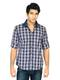

In [3]:
# Import BytesIO so image bytes can be treated like a file.
from io import BytesIO

# Import Image so we can open and inspect the product image.
from PIL import Image

# Select the first product from the DataFrame.
sample_product = products_df.iloc[0]

# Display basic product metadata.
print("Product ID:", sample_product["id"])
print("Product name:", sample_product["productDisplayName"])
print("Category:", sample_product["masterCategory"])
print("Subcategory:", sample_product["subCategory"])

# Get the embedded image object from the dataset.
image_data = sample_product["image"]

# Check what information is stored inside the image object.
print("Image object keys:", image_data.keys())

# Extract the raw image bytes.
image_bytes = image_data["bytes"]

# Convert the bytes into an image.
sample_image = Image.open(BytesIO(image_bytes))

# Display the image format and dimensions.
print("Image format:", sample_image.format)
print("Image size:", sample_image.size)

# Display the image inside the notebook.
display(sample_image)

## Step 3 — Encode the product image

The API cannot receive a local file path directly.

I will convert the image bytes into a Base64 string. This allows the image to be included inside an API request.

In [4]:
# Import base64 to encode binary image data as text.
import base64

# Define a reusable function for encoding image bytes.
def encode_image_to_base64(image_bytes):
    # Convert the image bytes into a Base64 string.
    encoded_image = base64.b64encode(image_bytes).decode("utf-8")
    
    # Return the encoded image string.
    return encoded_image

# Encode the sample image.
encoded_image = encode_image_to_base64(image_bytes)

# Display the size of the encoded image.
print("Encoded image length:", len(encoded_image))

# Display only the beginning of the string.
# We do not print the entire image because it would be extremely long.
print("Encoded image prefix:", encoded_image[:50] + "...")

Encoded image length: 1968
Encoded image prefix: /9j/4AAQSkZJRgABAQAAZABkAAD/7AARRHVja3kAAQAEAAAAJw...


## Step 4 — Design the product-listing prompt

The prompt tells the vision model:

- What role it should perform
- Which product information is known
- What it should analyze in the image
- What format the answer must use

In [5]:
# Define a function that creates a prompt for one product.
def create_product_listing_prompt(product):
    # Read useful metadata from the product row.
    product_name = product["productDisplayName"]
    category = product["masterCategory"]
    subcategory = product["subCategory"]
    article_type = product["articleType"]
    colour = product["baseColour"]
    usage = product["usage"]

    # Build the instruction that will be sent together with the image.
    prompt = f"""
# Role
You are an expert e-commerce copywriter.

# Product information
- Product name: {product_name}
- Main category: {category}
- Subcategory: {subcategory}
- Article type: {article_type}
- Colour: {colour}
- Usage: {usage}

# Task
Analyze the attached product image and create a professional product listing.

# Required response format
Return only valid JSON with these four keys:

{{
    "title": "SEO-friendly title with a maximum of 60 characters",
    "description": "Persuasive product description of 100 to 150 words",
    "features": [
        "Feature 1",
        "Feature 2",
        "Feature 3",
        "Feature 4",
        "Feature 5"
    ],
    "keywords": "10 to 15 comma-separated SEO keywords"
}}

# Important rules
- Mention only details visible in the image or provided metadata.
- Do not invent measurements, materials, brands, or performance claims.
- Describe visible colours, patterns, shape, and design details.
"""

    # Return the completed prompt.
    return prompt

# Create a prompt for the sample product.
sample_prompt = create_product_listing_prompt(sample_product)

# Display the prompt so we can review it before using the API.
print(sample_prompt)


# Role
You are an expert e-commerce copywriter.

# Product information
- Product name: Turtle Check Men Navy Blue Shirt
- Main category: Apparel
- Subcategory: Topwear
- Article type: Shirts
- Colour: Navy Blue
- Usage: Casual

# Task
Analyze the attached product image and create a professional product listing.

# Required response format
Return only valid JSON with these four keys:

{
    "title": "SEO-friendly title with a maximum of 60 characters",
    "description": "Persuasive product description of 100 to 150 words",
    "features": [
        "Feature 1",
        "Feature 2",
        "Feature 3",
        "Feature 4",
        "Feature 5"
    ],
    "keywords": "10 to 15 comma-separated SEO keywords"
}

# Important rules
- Mention only details visible in the image or provided metadata.
- Do not invent measurements, materials, brands, or performance claims.
- Describe visible colours, patterns, shape, and design details.



## Step 5 — Call the OpenAI vision model

I will send two inputs to the model:

1. The product-listing prompt
2. The product image encoded as a Base64 data URL

The model will return a product listing in JSON format.

In [6]:
# Define the MIME type of the sample image.
image_mime_type = "image/jpeg"

# Create a data URL containing the image format and Base64 image data.
image_data_url = f"data:{image_mime_type};base64,{encoded_image}"

# Send the prompt and image to the OpenAI vision model.
response = client.responses.create(
    # Use a vision-capable model.
    model="gpt-4.1-mini",
    
    # Send the prompt and image together as one user message.
    input=[
        {
            "role": "user",
            "content": [
                {
                    # Send the product-listing instructions.
                    "type": "input_text",
                    "text": sample_prompt,
                },
                {
                    # Send the product image.
                    "type": "input_image",
                    "image_url": image_data_url,
                },
            ],
        }
    ],
)

# Extract the model's text response.
raw_listing = response.output_text

# Display the generated response.
print(raw_listing)

{
  "title": "Turtle Check Men Navy Blue Checked Casual Shirt",
  "description": "Elevate your casual wardrobe with the Turtle Check Men Navy Blue Shirt. Featuring a classic checkered pattern in navy blue and white, this shirt offers a timeless style perfect for everyday wear. Designed with a button-down front and a neatly structured collar, it ensures a crisp and polished look. The full sleeves with buttoned cuffs provide versatility for different occasions and weather conditions. Crafted for comfort and style, this shirt pairs effortlessly with jeans or chinos for a relaxed yet refined appearance.",
  "features": [
    "Navy blue and white checkered pattern",
    "Button-down front with classic collar",
    "Full sleeves with buttoned cuffs",
    "Casual fit suitable for everyday use",
    "Lightweight and breathable fabric appearance"
  ],
  "keywords": "men's casual shirt, navy blue shirt, checkered shirt, full sleeve shirt, button-down shirt, men's topwear, casual wear, men's chec

### Parse and validate the API response

The API response is text, even though the model was asked to return JSON.

I will convert that text into a Python dictionary so I can access each field separately.

In [7]:
# Import json so we can parse the model's JSON text.
import json

# Remove unnecessary whitespace from the response.
clean_listing_text = raw_listing.strip()

# Remove Markdown code fences if the model added them.
if clean_listing_text.startswith("```"):
    # Remove the first line containing ```json or ```.
    clean_listing_text = clean_listing_text.split("\n", 1)[1]
    
    # Remove the closing code fence.
    clean_listing_text = clean_listing_text.rsplit("```", 1)[0].strip()

# Convert the JSON text into a Python dictionary.
listing = json.loads(clean_listing_text)

# Define the fields that every listing must contain.
required_fields = ["title", "description", "features", "keywords"]

# Check whether any required fields are missing.
missing_fields = [
    field for field in required_fields
    if field not in listing
]

# Stop if the response is incomplete.
if missing_fields:
    raise ValueError(f"Missing fields: {missing_fields}")

# Display the generated listing in a readable format.
print("Title:", listing["title"])
print("\nDescription:", listing["description"])
print("\nFeatures:")
for feature in listing["features"]:
    print("-", feature)
print("\nKeywords:", listing["keywords"])

Title: Turtle Check Men Navy Blue Checked Casual Shirt

Description: Elevate your casual wardrobe with the Turtle Check Men Navy Blue Shirt. Featuring a classic checkered pattern in navy blue and white, this shirt offers a timeless style perfect for everyday wear. Designed with a button-down front and a neatly structured collar, it ensures a crisp and polished look. The full sleeves with buttoned cuffs provide versatility for different occasions and weather conditions. Crafted for comfort and style, this shirt pairs effortlessly with jeans or chinos for a relaxed yet refined appearance.

Features:
- Navy blue and white checkered pattern
- Button-down front with classic collar
- Full sleeves with buttoned cuffs
- Casual fit suitable for everyday use
- Lightweight and breathable fabric appearance

Keywords: men's casual shirt, navy blue shirt, checkered shirt, full sleeve shirt, button-down shirt, men's topwear, casual wear, men's check shirt, navy check shirt, Turtle Check shirt, men's 

## Step 6 — Add error handling

API requests can fail because of:

- Missing images
- Invalid API keys
- Network problems
- Rate limits
- Invalid JSON responses

I will create a function that catches errors and retries temporary failures.

In [8]:
# Import time so we can wait between retry attempts.
import time

# Define a function that sends one product to the vision model.
def generate_listing_for_product(product, max_retries=2):
    # Get the image information from the product row.
    product_image_data = product["image"]

    # Check that the product contains image bytes.
    if not product_image_data or not product_image_data.get("bytes"):
        raise ValueError("This product does not contain image bytes.")

    # Extract the image bytes.
    product_image_bytes = product_image_data["bytes"]

    # Encode the image bytes as Base64 text.
    product_encoded_image = base64.b64encode(
        product_image_bytes
    ).decode("utf-8")

    # Create a data URL for the image.
    product_image_url = (
        f"data:image/jpeg;base64,{product_encoded_image}"
    )

    # Create a prompt for this product.
    product_prompt = create_product_listing_prompt(product)

    # Try the API request more than once if an error occurs.
    for attempt in range(max_retries + 1):
        try:
            # Send the product prompt and image to the vision model.
            product_response = client.responses.create(
                model="gpt-4.1-mini",
                input=[
                    {
                        "role": "user",
                        "content": [
                            {
                                "type": "input_text",
                                "text": product_prompt,
                            },
                            {
                                "type": "input_image",
                                "image_url": product_image_url,
                            },
                        ],
                    }
                ],
            )

            # Extract the response text.
            product_raw_listing = product_response.output_text.strip()

            # Remove Markdown code fences if present.
            if product_raw_listing.startswith("```"):
                product_raw_listing = product_raw_listing.split(
                    "\n", 1
                )[1]
                product_raw_listing = product_raw_listing.rsplit(
                    "```", 1
                )[0].strip()

            # Convert the response into a Python dictionary.
            product_listing = json.loads(product_raw_listing)

            # Return the successful listing.
            return product_listing

        except Exception as error:
            # Display which attempt failed.
            print(f"Attempt {attempt + 1} failed: {error}")

            # If retries remain, wait before trying again.
            if attempt < max_retries:
                wait_seconds = 2 ** attempt
                print(f"Retrying in {wait_seconds} seconds...")
                time.sleep(wait_seconds)

            # If no retries remain, return the error to the caller.
            else:
                raise RuntimeError(
                    "Could not generate a listing for this product."
                ) from error

## Step 7 — Generate listings for multiple products

I will now process three products in a loop.

For each product, the notebook will:

1. Send the image and metadata to the model.
2. Generate a listing.
3. Store the result.
4. Continue even if one product fails.

In [9]:
# Create an empty list to store all generated results.
all_listings = []

# Select the first three products for the batch.
products_to_process = products_df.head(3)

# Loop through each selected product.
for row_number, (_, product) in enumerate(
    products_to_process.iterrows(),
    start=1
):
    # Display which product is currently being processed.
    print(
        f"Processing product {row_number}/"
        f"{len(products_to_process)}: "
        f"{product['productDisplayName']}"
    )

    # Create a basic result record with product information.
    result = {
        "product_id": int(product["id"]),
        "product_name": product["productDisplayName"],
    }

    try:
        # Generate a product listing using the error-handling function.
        generated_listing = generate_listing_for_product(product)

        # Store the successful listing.
        result["listing"] = generated_listing

        # Record the successful status.
        result["status"] = "success"

        # Confirm success.
        print("Status: success")

    except Exception as error:
        # Store the error instead of stopping the entire batch.
        result["status"] = "error"
        result["error"] = str(error)

        # Display the error.
        print("Status: error")
        print(error)

    # Add the result to the complete results list.
    all_listings.append(result)

    # Wait briefly before the next request.
    time.sleep(1)

# Display a summary of the batch.
print("\nBatch processing complete.")
print("Total products processed:", len(all_listings))
print(
    "Successful products:",
    sum(item["status"] == "success" for item in all_listings)
)
print(
    "Failed products:",
    sum(item["status"] == "error" for item in all_listings)
)

Processing product 1/3: Turtle Check Men Navy Blue Shirt
Status: success
Processing product 2/3: Peter England Men Party Blue Jeans
Status: success
Processing product 3/3: Titan Women Silver Watch
Status: success

Batch processing complete.
Total products processed: 3
Successful products: 3
Failed products: 0


## Step 8 — Save the results

The generated listings currently exist only in notebook memory.

I will save them as a JSON file so they can be reused by an e-commerce system.

In [10]:
# Import json so the results can be saved in JSON format.
import json

# Define the output folder.
output_folder = PROJECT_DIR / "outputs"

# Create the output folder if it does not already exist.
output_folder.mkdir(exist_ok=True)

# Define the output file path.
output_file = output_folder / "notebook_product_listings.json"

# Open the output file for writing.
with open(output_file, "w", encoding="utf-8") as file:
    # Save all listings with readable indentation.
    json.dump(
        all_listings,
        file,
        indent=2,
        ensure_ascii=False
    )

# Confirm where the file was saved.
print(f"Listings saved to: {output_file}")

Listings saved to: /Users/tamdod/Documents/VS_Code_Projects/api_calling_to_chatgpt/outputs/notebook_product_listings.json


In [11]:
# Open the saved JSON file again.
with open(output_file, "r", encoding="utf-8") as file:
    # Load the saved listings back into Python.
    saved_listings = json.load(file)

# Display how many listings were saved.
print("Saved listings:", len(saved_listings))

# Display the first saved product title.
print(
    "First title:",
    saved_listings[0]["listing"]["title"]
)

Saved listings: 3
First title: Turtle Check Men Navy Blue Casual Shirt


## Step 9 — Test an error scenario

I will simulate a product with missing image data.

This test should fail safely and show an error message instead of crashing the entire batch.

In [12]:
# Create a copy of the first product.
broken_product = products_df.iloc[0].copy()

# Remove its image bytes to simulate damaged or missing image data.
broken_product["image"] = {"bytes": None}

# Try to process the broken product.
try:
    # This should raise an error because the image is missing.
    generate_listing_for_product(broken_product)

# Catch the expected error.
except Exception as error:
    # Display the error message.
    print("Error handled successfully.")
    print("Error type:", type(error).__name__)
    print("Error message:", error)

Error handled successfully.
Error type: ValueError
Error message: This product does not contain image bytes.


## Step 10 — Final verification

The lab is complete when:

- The API client initializes successfully.
- Product metadata and images load correctly.
- Images are encoded as Base64.
- A prompt is sent with text and an image.
- The response is parsed as JSON.
- Three products are processed successfully.
- Results are saved to a JSON file.
- An error scenario is handled safely.

In [13]:
# Check that all three products were processed.
assert len(all_listings) == 3

# Check that all products completed successfully.
assert all(
    item["status"] == "success"
    for item in all_listings
)

# Check that every listing contains the required fields.
for item in all_listings:
    # Get the generated listing.
    generated_listing = item["listing"]

    # Confirm that all required fields are present.
    assert "title" in generated_listing
    assert "description" in generated_listing
    assert "features" in generated_listing
    assert "keywords" in generated_listing

# Confirm that the output file exists.
assert output_file.exists()

# Display the final verification message.
print("All final verification checks passed.")
print("The notebook workflow is complete.")

All final verification checks passed.
The notebook workflow is complete.


## Learning reflection

- I learned that API integration requires authentication, request preparation, response handling, and error handling.
- Base64 encoding allows images to be sent to the vision model as data URLs.
- Prompt design affects the quality and consistency of the generated listings.
- Batch processing saves time compared with writing each listing manually.
- API keys must be stored securely and never committed to version control.
- Retry logic helps make API workflows more reliable.

# Lab Extension — JSON Validation with Pydantic

## Step 1 — Setting Up Pydantic

Pydantic validates Python data using clearly defined models and rules.
First, I will install the Pydantic package.

In [1]:
# Install Pydantic in the current Jupyter kernel.
%pip install pydantic

Note: you may need to restart the kernel to use updated packages.


### Create a simple product validation model

A Pydantic model defines:

- Which fields are required
- Which data types are expected
- Which values are allowed

In [1]:
# Import the base class used to create Pydantic models.
from pydantic import BaseModel, Field, ValidationError

# Define a simple product model.
class SimpleProduct(BaseModel):
    # Require a product name with at least one character.
    name: str = Field(min_length=1)

    # Require a price greater than zero.
    price: float = Field(gt=0)

    # Require a quantity greater than zero.
    # If no quantity is provided, use 1 as the default.
    quantity: int = Field(default=1, gt=0)

# Create a valid product.
valid_product = SimpleProduct(
    name="Widget",
    price=10.99,
    quantity=5
)

# Display the validated product.
print("Valid product:")
print(valid_product)

Valid product:
name='Widget' price=10.99 quantity=5


### Test invalid product data

Now I will provide an invalid negative price.

Pydantic should reject the data and provide a clear validation error.

In [2]:
# Try to create a product with an invalid negative price.
try:
    # This should fail because the price must be greater than zero.
    invalid_product = SimpleProduct(
        name="Widget",
        price=-10.99,
        quantity=5
    )

# Catch the expected Pydantic validation error.
except ValidationError as error:
    # Display a clear message confirming the error was handled.
    print("Validation error handled successfully.")

    # Display the detailed validation error.
    print(error)

Validation error handled successfully.
1 validation error for SimpleProduct
price
  Input should be greater than 0 [type=greater_than, input_value=-10.99, input_type=float]
    For further information visit https://errors.pydantic.dev/2.14/v/greater_than


## Step 2 — Create product data models

I will now create models for:

1. Incoming product requests
2. Generated product listings

These models will define the expected structure and validation rules.

In [3]:
# Import Optional so some fields can be omitted.
from typing import Optional

# Import field_validator for custom validation rules.
from pydantic import BaseModel, Field, field_validator

# Define the structure of an incoming product request.
class ProductRequest(BaseModel):
    # Require a non-empty product name.
    name: str = Field(min_length=1, max_length=150)

    # Require a positive product price.
    price: float = Field(gt=0)

    # Require a non-empty product category.
    category: str = Field(min_length=1, max_length=100)

    # Allow optional extra information about the product.
    additional_info: Optional[str] = None

    # Require image data encoded as a Base64 string.
    image_base64: str = Field(min_length=20)

    # Remove unnecessary spaces from text fields.
    @field_validator("name", "category")
    @classmethod
    def text_must_not_be_blank(cls, value):
        # Remove spaces at the beginning and end.
        cleaned_value = value.strip()

        # Reject values that contain only spaces.
        if not cleaned_value:
            raise ValueError("This field cannot be blank.")

        # Return the cleaned value.
        return cleaned_value

# Define the structure expected from the ChatGPT response.
class ProductListing(BaseModel):
    # Require a title with a maximum length of 60 characters.
    title: str = Field(min_length=1, max_length=60)

    # Require a product description.
    description: str = Field(min_length=1)

    # Require between 1 and 7 product features.
    features: list[str] = Field(min_length=1, max_length=7)

    # Require a non-empty keyword string.
    keywords: str = Field(min_length=1)

# Display the model field definitions.
print("Product request fields:")
print(ProductRequest.model_fields)

print("\nProduct listing fields:")
print(ProductListing.model_fields)

Product request fields:
{'name': FieldInfo(annotation=str, required=True, metadata=[MinLen(min_length=1), MaxLen(max_length=150)]), 'price': FieldInfo(annotation=float, required=True, metadata=[Gt(gt=0)]), 'category': FieldInfo(annotation=str, required=True, metadata=[MinLen(min_length=1), MaxLen(max_length=100)]), 'additional_info': FieldInfo(annotation=Union[str, NoneType], required=False, default=None), 'image_base64': FieldInfo(annotation=str, required=True, metadata=[MinLen(min_length=20)])}

Product listing fields:
{'title': FieldInfo(annotation=str, required=True, metadata=[MinLen(min_length=1), MaxLen(max_length=60)]), 'description': FieldInfo(annotation=str, required=True, metadata=[MinLen(min_length=1)]), 'features': FieldInfo(annotation=list[str], required=True, metadata=[MinLen(min_length=1), MaxLen(max_length=7)]), 'keywords': FieldInfo(annotation=str, required=True, metadata=[MinLen(min_length=1)])}


### Test the product models

I will test:

- A valid product request
- An invalid request with a negative price
- An invalid request with a blank name

In [4]:
# Create valid sample data.
valid_product_data = {
    "name": "Wireless Headphones",
    "price": 79.99,
    "category": "Electronics",
    "additional_info": "Noise cancelling and 30-hour battery",
    "image_base64": "a" * 20
}

# Validate the sample data using the ProductRequest model.
valid_request = ProductRequest(**valid_product_data)

# Display the validated request.
print("Valid request accepted:")
print(valid_request)

Valid request accepted:
name='Wireless Headphones' price=79.99 category='Electronics' additional_info='Noise cancelling and 30-hour battery' image_base64='aaaaaaaaaaaaaaaaaaaa'


In [5]:
# Create invalid sample data.
invalid_product_data = {
    "name": "   ",
    "price": -10,
    "category": "Electronics",
    "image_base64": "a" * 20
}

# Try to validate the invalid data.
try:
    # This should fail because the name is blank and price is negative.
    invalid_request = ProductRequest(**invalid_product_data)

# Catch the expected validation error.
except ValidationError as error:
    # Confirm that invalid data was rejected.
    print("Invalid request rejected successfully.")

    # Display the validation details.
    for problem in error.errors():
        print(problem["loc"], "-", problem["msg"])

Invalid request rejected successfully.
('name',) - Value error, This field cannot be blank.
('price',) - Input should be greater than 0


## Step 3 — Validate JSON input

In this step, I will create:

- One valid JSON request
- One invalid JSON request

Then I will load and validate both files.

In [7]:
# Import Path so we can create project file paths.
from pathlib import Path

# Identify the current project folder again.
PROJECT_DIR = Path.cwd()

In [8]:
# Import json so Python can create and read JSON files.
import json

# Create a folder for the example JSON request files.
json_folder = PROJECT_DIR / "json_examples"
json_folder.mkdir(exist_ok=True)

# Define a valid product request.
valid_json_data = {
    "name": "Wireless Headphones",
    "price": 79.99,
    "category": "Electronics",
    "additional_info": "Noise cancelling and 30-hour battery",
    "image_base64": "a" * 20
}

# Define an invalid product request.
invalid_json_data = {
    "name": "",
    "price": -20,
    "category": "Electronics",
    "image_base64": "a" * 20
}

# Define the valid JSON file path.
valid_json_file = json_folder / "valid_product.json"

# Define the invalid JSON file path.
invalid_json_file = json_folder / "invalid_product.json"

# Save the valid data as formatted JSON.
valid_json_file.write_text(
    json.dumps(valid_json_data, indent=2),
    encoding="utf-8"
)

# Save the invalid data as formatted JSON.
invalid_json_file.write_text(
    json.dumps(invalid_json_data, indent=2),
    encoding="utf-8"
)

# Confirm that both files were created.
print("Created:", valid_json_file)
print("Created:", invalid_json_file)

Created: /Users/tamdod/Documents/VS_Code_Projects/api_calling_with_json/json_examples/valid_product.json
Created: /Users/tamdod/Documents/VS_Code_Projects/api_calling_with_json/json_examples/invalid_product.json


### Load and validate JSON files

I will create a reusable function that:

1. Opens a JSON file
2. Parses the JSON content
3. Validates it with `ProductRequest`
4. Reports validation errors clearly

In [9]:
# Define a function that loads and validates one JSON file.
def load_and_validate_json(file_path):
    # Open the JSON file for reading.
    with open(file_path, "r", encoding="utf-8") as file:
        # Convert the JSON text into a Python dictionary.
        raw_data = json.load(file)

    # Validate the dictionary using the ProductRequest model.
    validated_product = ProductRequest(**raw_data)

    # Return the validated Pydantic object.
    return validated_product

# Test the valid JSON file.
try:
    # Load and validate the valid product.
    validated_product = load_and_validate_json(valid_json_file)

    # Display the validated result.
    print("Valid JSON accepted successfully.")
    print(validated_product)

# Catch validation errors.
except ValidationError as error:
    # Display any validation problems.
    print("Validation error:", error)

Valid JSON accepted successfully.
name='Wireless Headphones' price=79.99 category='Electronics' additional_info='Noise cancelling and 30-hour battery' image_base64='aaaaaaaaaaaaaaaaaaaa'


In [10]:
# Try to load and validate the invalid JSON file.
try:
    # This should fail because the name is blank and price is negative.
    invalid_product = load_and_validate_json(invalid_json_file)

# Catch the expected validation error.
except ValidationError as error:
    # Confirm that invalid JSON was rejected.
    print("Invalid JSON rejected successfully.")

    # Display each validation problem clearly.
    for problem in error.errors():
        print(problem["loc"], "-", problem["msg"])

Invalid JSON rejected successfully.
('name',) - String should have at least 1 character
('price',) - Input should be greater than 0


In [12]:
# Import pandas to load the dataset.
import pandas as pd

# Import base64 to encode the product image.
import base64

# Define the dataset path.
dataset_path = PROJECT_DIR / "data" / "train-00000-of-00002-6cff4c59f91661c3.parquet"

# Load the dataset into a DataFrame.
products_df = pd.read_parquet(dataset_path)

# Select the first product.
sample_product = products_df.iloc[0]

# Extract the embedded image bytes.
image_bytes = sample_product["image"]["bytes"]

# Encode the image bytes as Base64 text.
encoded_image = base64.b64encode(image_bytes).decode("utf-8")

# Confirm that the required variables were recreated.
print("Sample product restored:", sample_product["productDisplayName"])
print("Image encoded successfully:", len(encoded_image), "characters")

Sample product restored: Turtle Check Men Navy Blue Shirt
Image encoded successfully: 1968 characters


## Step 4 — Integrate validation with the ChatGPT workflow

Before calling the API, I will validate the incoming product request.

Only validated requests should continue to API processing.

In [13]:
# Create a product request using the sample product metadata.
api_request_data = {
    # Use the product name from the dataset.
    "name": sample_product["productDisplayName"],

    # The dataset does not contain prices, so provide a sample price.
    "price": 79.99,

    # Use the main product category from the dataset.
    "category": sample_product["masterCategory"],

    # Add extra information from the dataset.
    "additional_info": (
        f"Colour: {sample_product['baseColour']}; "
        f"Usage: {sample_product['usage']}"
    ),

    # Use the real Base64 image created earlier.
    "image_base64": encoded_image,
}

# Validate the incoming request with Pydantic.
validated_api_request = ProductRequest(**api_request_data)

# Confirm that validation succeeded.
print("API request validated successfully.")

# Display the validated product information.
print("Product:", validated_api_request.name)
print("Price:", validated_api_request.price)
print("Category:", validated_api_request.category)

API request validated successfully.
Product: Turtle Check Men Navy Blue Shirt
Price: 79.99
Category: Apparel


### Process the validated request

The API call will only happen after the product data passes Pydantic validation.

After receiving the response, I will validate the generated listing with `ProductListing`.

In [15]:
# Import os to read environment variables.
import os

# Import Path to locate the project folder.
from pathlib import Path

# Import dotenv to load the .env file.
from dotenv import load_dotenv

# Import the OpenAI client.
from openai import OpenAI

# Recreate the project path after the kernel restart.
PROJECT_DIR = Path.cwd()

# Load the local .env file.
load_dotenv(PROJECT_DIR / ".env")

# Read the API key without printing it.
api_key = os.getenv("OPENAI_API_KEY")

# Stop if the API key was not found.
if not api_key:
    raise ValueError("OPENAI_API_KEY was not found.")

# Recreate the OpenAI client.
client = OpenAI(api_key=api_key)

# Confirm that this cell ran successfully.
print("OpenAI client restored successfully.")

OpenAI client restored successfully.


In [17]:
# Create a prompt from the validated product request.
validated_prompt = f"""
You are an expert e-commerce copywriter.

Product name: {validated_api_request.name}
Price: ${validated_api_request.price:.2f}
Category: {validated_api_request.category}
Additional information: {validated_api_request.additional_info}

Analyze the attached image and return only valid JSON with these keys:

{{
    "title": "SEO-friendly title with a maximum of 50 characters. Count the characters carefully.",
    "description": "A persuasive product description",
    "features": ["Five concise product features"],
    "keywords": "Comma-separated SEO keywords"
}}

Only mention details visible in the image or provided information.
"""

# Create a data URL from the validated Base64 image.
validated_image_url = (
    f"data:image/jpeg;base64,{validated_api_request.image_base64}"
)

# Send the validated request to the OpenAI vision model.
validated_response = client.responses.create(
    # Select the vision-capable model.
    model="gpt-4.1-mini",

    # Send the validated prompt and image.
    input=[
        {
            "role": "user",
            "content": [
                {
                    "type": "input_text",
                    "text": validated_prompt,
                },
                {
                    "type": "input_image",
                    "image_url": validated_image_url,
                },
            ],
        }
    ],
)

# Extract the model response text.
validated_raw_output = validated_response.output_text.strip()

# Remove Markdown code fences if the model added them.
if validated_raw_output.startswith("```"):
    # Remove the opening code fence.
    validated_raw_output = validated_raw_output.split("\n", 1)[1]

    # Remove the closing code fence.
    validated_raw_output = validated_raw_output.rsplit(
        "```",
        1
    )[0].strip()

# Convert the response text into a Python dictionary.
validated_output_data = json.loads(validated_raw_output)

# Validate the API output with the ProductListing model.
validated_listing = ProductListing(**validated_output_data)

# Confirm that both input and output validation succeeded.
print("Input validation: successful")
print("API processing: successful")
print("Output validation: successful")

# Display the validated title.
print("Generated title:", validated_listing.title)

Input validation: successful
API processing: successful
Output validation: successful
Generated title: Turtle Check Men's Navy Blue Casual Shirt


## Step 5 — Handle multiple requests

I will process a batch containing:

- One valid request
- One invalid request

The invalid request should produce a structured error without stopping the batch.

In [18]:
# Create a list containing both valid and invalid requests.
batch_request_data = [
    valid_json_data,
    invalid_json_data
]

# Define the batch JSON file path.
batch_json_file = json_folder / "batch_requests.json"

# Save the batch requests to a JSON file.
batch_json_file.write_text(
    json.dumps(batch_request_data, indent=2),
    encoding="utf-8"
)

# Display the saved file path.
print("Batch file created:", batch_json_file)

Batch file created: /Users/tamdod/Documents/VS_Code_Projects/api_calling_with_json/json_examples/batch_requests.json


In [19]:
# Create an empty list for successful validations.
successful_requests = []

# Create an empty list for validation errors.
validation_errors = []

# Open the batch JSON file.
with open(batch_json_file, "r", encoding="utf-8") as file:
    # Load all requests from the file.
    batch_requests = json.load(file)

# Process each request separately.
for request_number, request_data in enumerate(
    batch_requests,
    start=1
):
    try:
        # Validate the current request.
        validated_request = ProductRequest(**request_data)

        # Store valid requests for later API processing.
        successful_requests.append(validated_request)

        # Display the successful result.
        print(f"Request {request_number}: valid")

    except ValidationError as error:
        # Store structured errors for this request.
        validation_errors.append({
            "request_number": request_number,
            "errors": error.errors()
        })

        # Display that the request was rejected.
        print(f"Request {request_number}: invalid")

# Display the final batch summary.
print("\nBatch summary:")
print("Valid requests:", len(successful_requests))
print("Invalid requests:", len(validation_errors))

Request 1: valid
Request 2: invalid

Batch summary:
Valid requests: 1
Invalid requests: 1


## Step 6 — Create a client request handler

The handler will provide one reusable entry point that:

1. Validates incoming data
2. Calls the ChatGPT API only for valid data
3. Validates the API output
4. Returns a consistent success or error response

In [20]:
# Define one reusable function for handling client requests.
def handle_client_request(payload):
    # Validate the incoming request before calling the API.
    try:
        validated_request = ProductRequest(**payload)

    # Return a predictable error response for invalid input.
    except ValidationError as error:
        return {
            "status": "error",
            "error_type": "validation_error",
            "details": error.errors()
        }

    # Create a prompt using the validated product data.
    prompt = f"""
You are an expert e-commerce copywriter.

Product name: {validated_request.name}
Price: ${validated_request.price:.2f}
Category: {validated_request.category}
Additional information: {validated_request.additional_info}

Analyze the attached image and return only valid JSON:

{{
    "title": "SEO-friendly title with a maximum of 50 characters",
    "description": "A persuasive product description",
    "features": ["Five concise product features"],
    "keywords": "Comma-separated SEO keywords"
}}

Only mention details supported by the image or product information.
"""

    # Create a data URL from the validated image.
    image_url = (
        f"data:image/jpeg;base64,"
        f"{validated_request.image_base64}"
    )

    # Call the OpenAI API only after input validation succeeds.
    try:
        response = client.responses.create(
            model="gpt-4.1-mini",
            input=[
                {
                    "role": "user",
                    "content": [
                        {
                            "type": "input_text",
                            "text": prompt
                        },
                        {
                            "type": "input_image",
                            "image_url": image_url
                        }
                    ]
                }
            ]
        )

        # Extract the model's text response.
        raw_output = response.output_text.strip()

        # Remove Markdown code fences if present.
        if raw_output.startswith("```"):
            raw_output = raw_output.split("\n", 1)[1]
            raw_output = raw_output.rsplit(
                "```",
                1
            )[0].strip()

        # Convert the response text into a dictionary.
        output_data = json.loads(raw_output)

        # Validate the generated output.
        validated_output = ProductListing(**output_data)

        # Return a consistent success response.
        return {
            "status": "success",
            "data": validated_output.model_dump()
        }

    # Catch API, JSON, or output-validation errors.
    except Exception as error:
        # Return a consistent processing error response.
        return {
            "status": "error",
            "error_type": "processing_error",
            "details": str(error)
        }

In [21]:
# Send the invalid request to the reusable handler.
invalid_handler_response = handle_client_request(
    invalid_json_data
)

# Display the handler response.
print(json.dumps(
    invalid_handler_response,
    indent=2
))

{
  "status": "error",
  "error_type": "validation_error",
  "details": [
    {
      "type": "string_too_short",
      "loc": [
        "name"
      ],
      "msg": "String should have at least 1 character",
      "input": "",
      "ctx": {
        "min_length": 1
      },
      "url": "https://errors.pydantic.dev/2.14/v/string_too_short"
    },
    {
      "type": "greater_than",
      "loc": [
        "price"
      ],
      "msg": "Input should be greater than 0",
      "input": -20,
      "ctx": {
        "gt": 0.0
      },
      "url": "https://errors.pydantic.dev/2.14/v/greater_than"
    }
  ]
}


In [22]:
# Send the validated product request to the reusable handler.
valid_handler_response = handle_client_request(
    api_request_data
)

# Display the complete handler response.
print(json.dumps(
    valid_handler_response,
    indent=2
))

{
  "status": "success",
  "data": {
    "title": "Turtle Check Navy Blue Casual Men's Shirt",
    "description": "Stay effortlessly stylish with the Turtle Check Men's Navy Blue Shirt. Perfect for casual outings, this comfortable and trendy checkered shirt adds a classic charm to your wardrobe.",
    "features": [
      "Premium quality casual shirt",
      "Navy blue checkered design",
      "Comfortable and breathable fabric",
      "Perfect for casual wear",
      "Tailored fit for men"
    ],
    "keywords": "men's navy blue shirt, casual men's shirt, checkered shirt, Turtle Check shirt, men's casual apparel"
  }
}


## Step 7 — Save validation results

I will save:

- The successful validated API response
- The batch validation summary
- The invalid-request error details

This creates evidence for the final submission.

In [23]:
# Define the output folder.
validation_output_folder = PROJECT_DIR / "outputs"

# Create the folder if it does not exist.
validation_output_folder.mkdir(exist_ok=True)

# Save the successful handler response.
successful_output_file = (
    validation_output_folder / "validated_request_result.json"
)

# Write the successful response to a JSON file.
successful_output_file.write_text(
    json.dumps(valid_handler_response, indent=2),
    encoding="utf-8"
)

# Create a summary of the batch validation.
batch_summary = {
    "total_requests": len(batch_requests),
    "valid_requests": len(successful_requests),
    "invalid_requests": len(validation_errors),
    "validation_errors": validation_errors
}

# Define the batch summary file.
batch_summary_file = (
    validation_output_folder / "batch_validation_summary.json"
)

# Save the batch summary.
batch_summary_file.write_text(
    json.dumps(batch_summary, indent=2),
    encoding="utf-8"
)

# Confirm that both files were saved.
print("Saved successful output:", successful_output_file)
print("Saved batch summary:", batch_summary_file)

Saved successful output: /Users/tamdod/Documents/VS_Code_Projects/api_calling_with_json/outputs/validated_request_result.json
Saved batch summary: /Users/tamdod/Documents/VS_Code_Projects/api_calling_with_json/outputs/batch_validation_summary.json


## Step 8 — Final verification

The workflow is complete when:

- Pydantic validates valid input.
- Invalid input is rejected with clear errors.
- Valid input reaches the API.
- API output is validated with Pydantic.
- Mixed batches are processed without stopping.
- Results are saved as JSON.

In [24]:
# Confirm that the valid handler request succeeded.
assert valid_handler_response["status"] == "success"

# Confirm that the invalid handler request was rejected.
assert invalid_handler_response["status"] == "error"

# Confirm that the batch contained both valid and invalid requests.
assert len(successful_requests) == 1
assert len(validation_errors) == 1

# Confirm that the saved output files exist.
assert successful_output_file.exists()
assert batch_summary_file.exists()

# Display the final verification result.
print("All validation workflow checks passed.")

All validation workflow checks passed.


## Learning reflection

- **Data validation:** Validation prevents incomplete, incorrect, or unsafe data from reaching the API.
- **Pydantic:** Pydantic provides automatic type checking, field rules, and clear validation errors.
- **Error handling:** Structured errors make problems easier to understand and fix.
- **Type safety:** Type hints define the expected data and make code more reliable.
- **API design:** Validating requests before processing improves reliability and prevents unnecessary API calls.
- **Best practices:** Validate input early, validate output, handle errors clearly, and save structured results.